<a href="https://colab.research.google.com/github/ferelsimanjorag/Rock-Fracture-Analysis/blob/main/Project_2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
# 1. Memesan koper perkakas AI bernama 'ultralytics' (menyediakan YOLO dan SAM)
!pip install ultralytics

# 2. Memanggil robot AI spesialis segmentasi
from ultralytics import FastSAM

# 3. Mengunduh "otak" AI yang sudah berpengalaman (Pre-trained model)
model = FastSAM('FastSAM-s.pt')

print("\n--- Otak AI sudah berhasil dipasang dan siap bekerja! ---")

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 13.9 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4/4 [ultralytics]
Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.

--- Otak AI sudah berhasil dipasang dan siap bekerja! ---



image 1/1 /content/batu1.jpg: 640x640 18 objects, 533.8ms
Speed: 2.8ms preprocess, 533.8ms inference, 29.9ms postprocess per image at shape (1, 3, 640, 640)


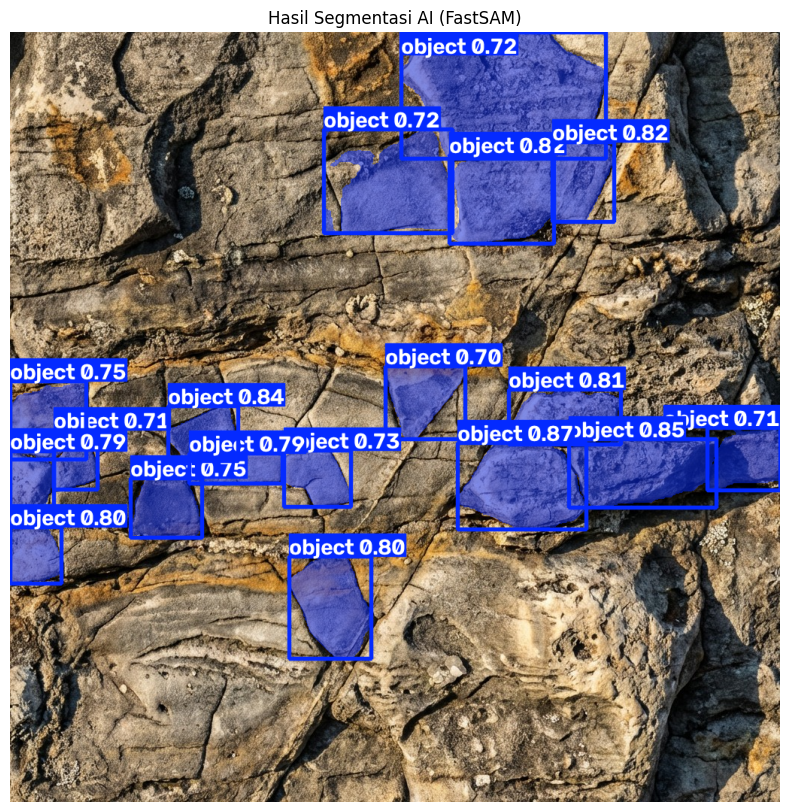

In [3]:
import cv2
import matplotlib.pyplot as plt

# 1. Menyuruh robot AI menganalisis gambar 'batu1.jpg'
hasil_prediksi = model('batu1.jpg', conf=0.7)

# 2. Meminta robot memberikan gambar yang sudah dia warnai/tandai
gambar_ai = hasil_prediksi[0].plot()

# 3. OpenCV kembali bertugas membalikkan warna BGR ke RGB agar normal
gambar_ai_rgb = cv2.cvtColor(gambar_ai, cv2.COLOR_BGR2RGB)

# 4. Memajang hasilnya ke layar
plt.figure(figsize=(10, 10))
plt.imshow(gambar_ai_rgb)
plt.title("Hasil Segmentasi AI (FastSAM)")
plt.axis('off')
plt.show()

Memulai prediksi AI untuk 5 gambar...


image 1/1 /content/batu5.jpg: 640x640 2 objects, 516.5ms
Speed: 2.2ms preprocess, 516.5ms inference, 3.9ms postprocess per image at shape (1, 3, 640, 640)


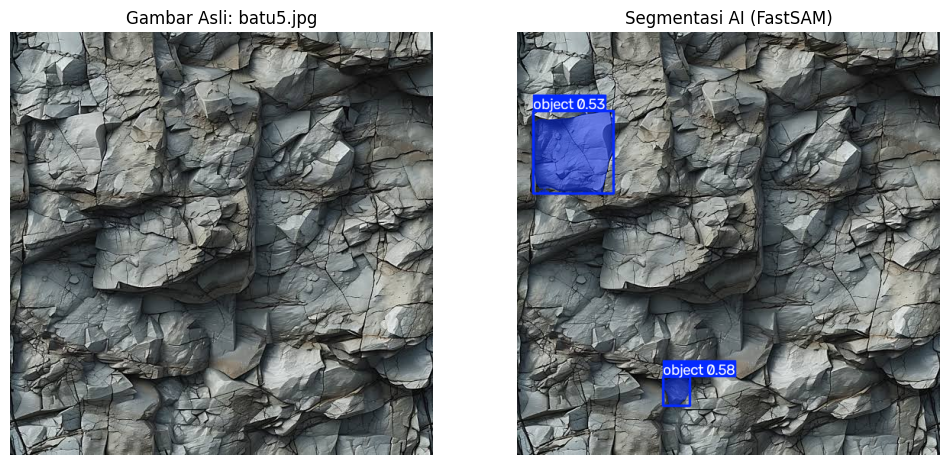


image 1/1 /content/batu1.jpg: 640x640 30 objects, 505.7ms
Speed: 4.1ms preprocess, 505.7ms inference, 50.4ms postprocess per image at shape (1, 3, 640, 640)


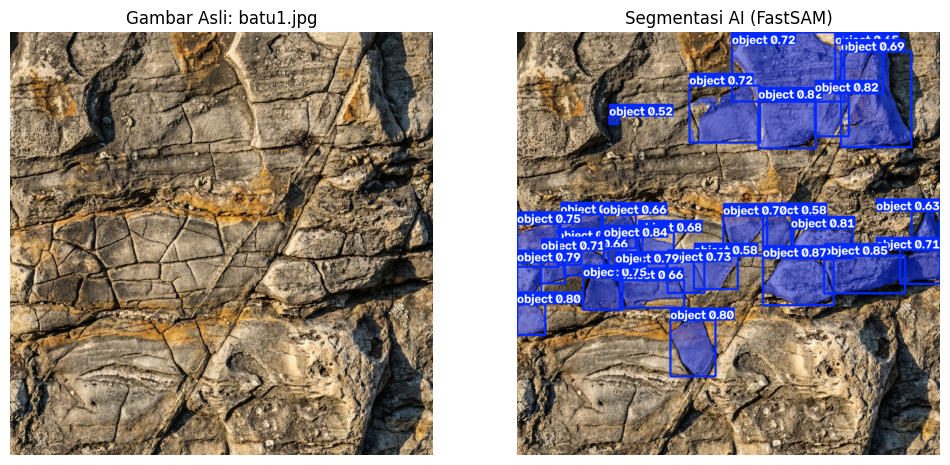


image 1/1 /content/batu4.jpg: 480x640 7 objects, 392.0ms
Speed: 2.4ms preprocess, 392.0ms inference, 7.4ms postprocess per image at shape (1, 3, 480, 640)


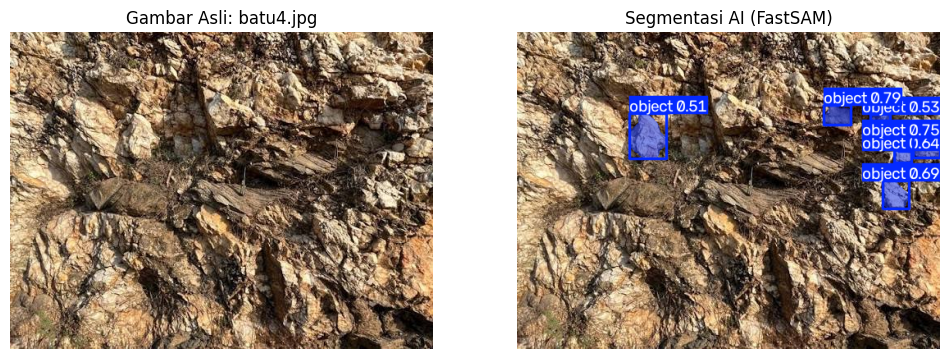


image 1/1 /content/batu2.jpg: 352x640 1 object, 295.1ms
Speed: 2.2ms preprocess, 295.1ms inference, 1.9ms postprocess per image at shape (1, 3, 352, 640)


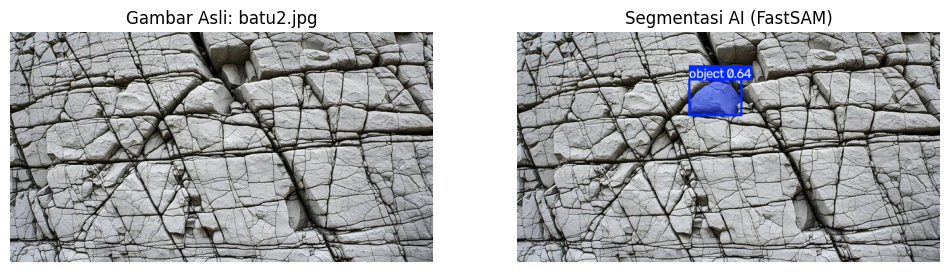


image 1/1 /content/batu3.jpg: 448x640 19 objects, 369.9ms
Speed: 2.1ms preprocess, 369.9ms inference, 18.4ms postprocess per image at shape (1, 3, 448, 640)


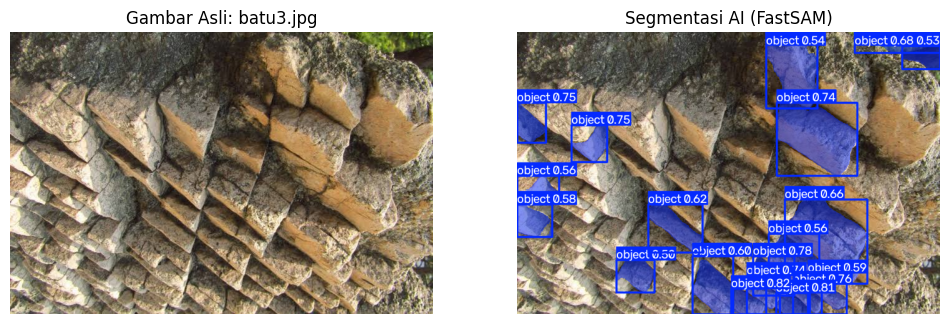


Beres! Semua gambar selesai dianalisis AI.


In [6]:
import glob

# 1. Mencari semua file .jpg di folder
daftar_gambar = glob.glob('*.jpg')
print(f"Memulai prediksi AI untuk {len(daftar_gambar)} gambar...\n")

# 2. Mengolah setiap gambar secara otomatis
for nama_file in daftar_gambar:
    # Membaca gambar asli untuk dipajang di kiri
    img_asli = cv2.imread(nama_file)
    img_asli_rgb = cv2.cvtColor(img_asli, cv2.COLOR_BGR2RGB)

    # Menyuruh AI memprediksi dan menggambar arsirannya (conf=0.7)
    hasil = model(nama_file, conf=0.5)
    img_ai = hasil[0].plot()
    img_ai_rgb = cv2.cvtColor(img_ai, cv2.COLOR_BGR2RGB)

    # Menyiapkan bingkai Before-After bersebelahan
    fig, ax = plt.subplots(1, 2, figsize=(12, 6))

    ax[0].imshow(img_asli_rgb)
    ax[0].set_title(f"Gambar Asli: {nama_file}")
    ax[0].axis('off')

    ax[1].imshow(img_ai_rgb)
    ax[1].set_title(f"Segmentasi AI (FastSAM)")
    ax[1].axis('off')

    plt.show()

print("\nBeres! Semua gambar selesai dianalisis AI.")